# Detecção de Anomalia com Self-Organizing Maps
Este notebook constrói um detector de anomalias não supervisionado baseado em SOM para as séries temporais de CPU e memória de um container do sistema MicroSS, do Dataset [GAIA (Generic AIOps Atlas)](https://github.com/CloudWise-OpenSource/GAIA-DataSet).


## O que é um SOM?
Um Self-Organizing Map (SOM) é uma rede neural não supervisionada formada por uma grade 2D de neurônios, onde cada neurônio tem um vetor de pesos com a mesma dimensão dos dados de entrada (aqui, 2 dimensões: CPU e memória).

## Como ele aprende?
A cada iteração de treinamento:
1. Sorteia-se uma amostra $x$ dos dados.
2. Encontra-se o neurônio cujo vetor de pesos é mais próximo de $x$ (Chamado de BMU, Best Matching Unit).
3. O BMU e seus vizinhos na grade têm seus vetores de pesos ajustados para se aproximarem de $x$.
4. Repete-se o processo para várias iterações até que a rede se organize de forma a refletir a topologia dos dados de entrada.

## Como isso vira detecção de anomalia?
Se o SOM for treinado com dados majoritariamente normais, seus neurônios representam o comportamento normal. Para uma nova amostra, podemos calcular o erro de quantização (QE), que é a distância entre a amostra e o vetor de pesos do BMU. Amostras com QE alto são consideradas anômalas.
Para isso precisamos também definir um limiar de QE acima do qual consideramos uma amostra como anômala.

> **Importante**: A premissa para o cenário não supervisionado é que anomalias são raras nos dados de treinamento. Se elas forem frequentes, o SOM pode acabar aprendendo a considerá-las como comportamento normal, prejudicando a detecção de anomalias.

# Configuração Inicial

In [49]:
# Importação de bibliotecas
import re
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Estilo dos gráficos
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [50]:
# Caminhos (relativos à pasta notebooks/)
DATA_DIR = Path('data')
INJECTION_FILE = Path('../datasets/GAIA-DataSet/MicroSS/run/run.zip')

# Serviço (container) do MicroSS a ser analisado
SERVICE = 'dbservice1'

# Divisão temporal dos dados - antes da data abaixo, o dado é usado para treino, a partir desta data, é usado para teste
SPLIT_DATE = '2021-08-01'

# Semente aleatória (reprodutibilidade: mesmos resultados a cada execução)
SEED = 42

# Carregamento dos dados

In [51]:
def load_metric(service, metric):
    # Lê e concatena todos os CSVs de uma métrica de um serviço.
    # Retorna uma pd.Series indexada por data/hora (UTC), ordenada e sem duplicatas.

    files = sorted(DATA_DIR.glob(f'{service}_*_docker_{metric}_*.csv'))
    print(f'{metric}: {len(files)} arquivos')

    data = pd.concat([pd.read_csv(f) for f in files])
    data['timestamp'] = pd.to_datetime(data['timestamp'], unit='ms')
    
    data = data.drop_duplicates('timestamp').set_index('timestamp').sort_index()
    
    return data['value'].rename(metric)


cpu = load_metric(SERVICE, 'cpu_total_norm')
mem = load_metric(SERVICE, 'memory_usage_pct')
cpu.head()

cpu_total_norm: 3 arquivos
memory_usage_pct: 3 arquivos


timestamp
2021-07-01 10:00:01    0.000105
2021-07-01 10:00:31    0.020737
2021-07-01 10:01:01    0.012239
2021-07-01 10:01:31    0.010190
2021-07-01 10:02:01    0.002135
Name: cpu_total_norm, dtype: float64

# Análise Exploratória
Antes de modelar, vamos conhecer os dados.

In [52]:
print('Periodo:', cpu.index.min(), 'até', cpu.index.max())
pd.concat([cpu.describe(), mem.describe()], axis=1)

Periodo: 2021-07-01 10:00:01 até 2021-08-31 15:59:34


,cpu_total_norm,memory_usage_pct
count,151828.000000,151543.000000
mean,0.163434,0.271586
std,0.174791,0.073756
min,0.000000,0.032098
25%,0.016525,0.224930
50%,0.040326,0.256390
75%,0.265373,0.309538
max,0.714677,0.707784


In [53]:
# Com que frequência as medições acontecem?
intervalos = cpu.index.to_series().diff()

print('Intervalos mais comuns na coleta das métricas de CPU:')
print(intervalos.value_counts().head(3))

print('\nMaiores lacunas:')
print(intervalos.nlargest(3))

# Verificar se CPU e memória são medidas nos mesmos instantes
in_common = cpu.index.intersection(mem.index)
print(f'\nInstantes em comum entre CPU e memória: {len(in_common)} de {len(cpu)}')

Intervalos mais comuns na coleta das métricas de CPU:
timestamp
0 days 00:00:30    151765
0 days 00:00:29         7
0 days 00:00:31         7
Name: count, dtype: int64

Maiores lacunas:
timestamp
2021-08-23 01:44:34   2 days 12:26:30
2021-07-30 08:21:00   1 days 16:21:00
2021-08-09 02:23:15   1 days 00:35:15
Name: timestamp, dtype: timedelta64[ns]

Instantes em comum entre CPU e memória: 8630 de 151828


- Os dados de CPU e memória não são medidos nos mesmos instantes.
  - Por conta disso, precisaremos alinhar os dados em uma grade temporal comum antes de formar os vetores de entrada para o modelo.

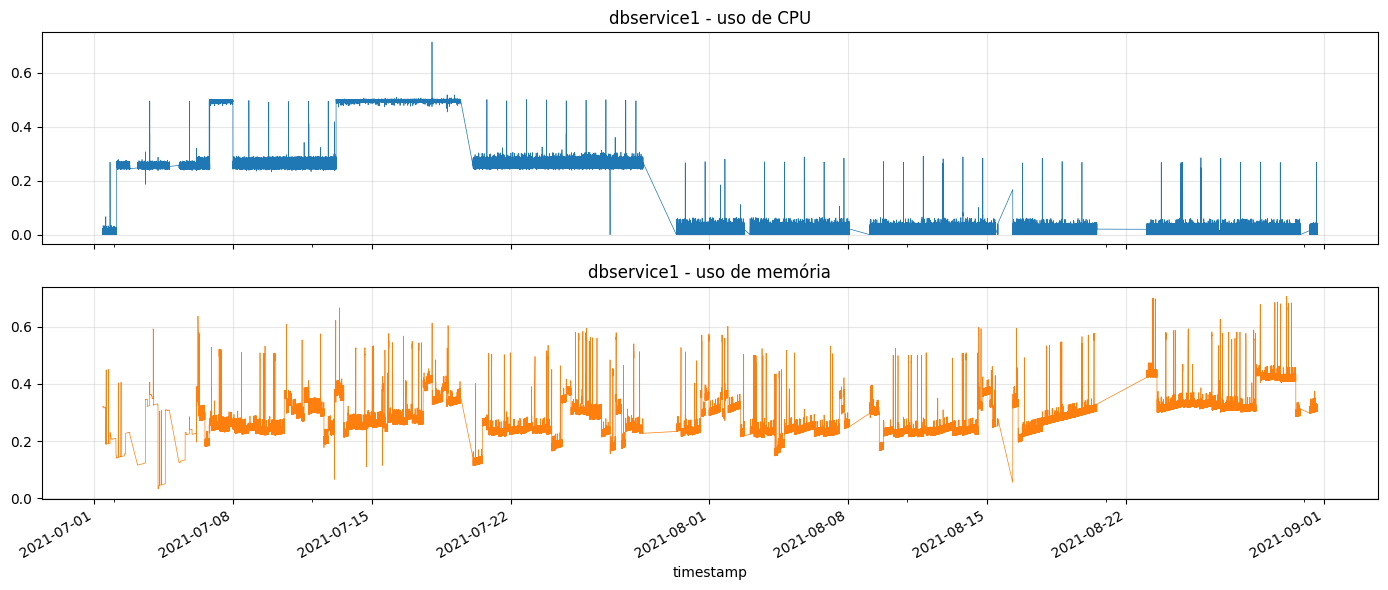

In [54]:
# Visualização do uso de CPU e memória ao longo do tempo
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
cpu.plot(ax=axes[0], lw=0.5, title=f'{SERVICE} - uso de CPU')
mem.plot(ax=axes[1], lw=0.5, color='tab:orange', title=f'{SERVICE} - uso de memória')
plt.tight_layout()

plt.show()

Identificável no gráfico:
- Memória tem uma linha de base estável, com alguns picos ocasionais, esses são candidatos a anomalias.
- CPU tem mudanças de patamar ao longo do tempo (repare como ele transita entre diferentes níveis de uso).
  - O que é considerado "normal" muda com o tempo. O que é um desafio em séries temporais que precisaremos levar em conta ao detectar anomalias.

# Pré-Processamento

## Alinhamento e Reamostragem

In [55]:
df = pd.concat([cpu, mem], axis=1)
df.columns = ['cpu', 'mem']
df = df.resample('1min').mean() # Reamostragem em intervvalos de 1 minuto (pegando a média nesse intervalo)

print('Valores ausentes após a reamostragem:')
print(df.isna().sum())

Valores ausentes após a reamostragem:
cpu    12266
mem    12259
dtype: int64


## Valores ausentes
Os minutos que não tiveram medição viram NaN.
Para lidar com isso, seguiremos a seguinte estratégia: 
- Dnterpolação linear para lacunas curtas (até 5 minutos)
- Descarte para lacunas longas.

In [56]:
df = df.interpolate(method='linear', limit=5).dropna()
print('Formato final:', df.shape)
df.head()

Formato final: (76054, 2)


,cpu,mem
timestamp,,
2021-07-01 10:00:00,0.010421,0.319730
2021-07-01 10:01:00,0.011214,0.319742
2021-07-01 10:02:00,0.011638,0.319756
2021-07-01 10:03:00,0.008505,0.319764
2021-07-01 10:04:00,0.010918,0.319776


## Divisão treino/teste
Aqui fazemos a divisão da série temporal em conjuntos de treino e teste com base na data de corte definida em `SPLIT_DATE`.

In [57]:
training = df[df.index < SPLIT_DATE]
test = df[df.index >= SPLIT_DATE]
print(f'Treino: {training.index.min()} até {training.index.max()}  ({len(training)} amostras)')
print(f'Teste:  {test.index.min()} até {test.index.max()}  ({len(test)} amostras)')

Treino: 2021-07-01 10:00:00 até 2021-07-31 23:59:00  (39342 amostras)
Teste:  2021-08-01 00:00:00 até 2021-08-31 15:59:00  (36712 amostras)
